# SQL-Based Analysis of Product Sales (Chinook)

This notebook connects to the Chinook SQLite database and uses SQL queries
to answer business questions about top-selling tracks, revenue by country
and monthly sales performance.

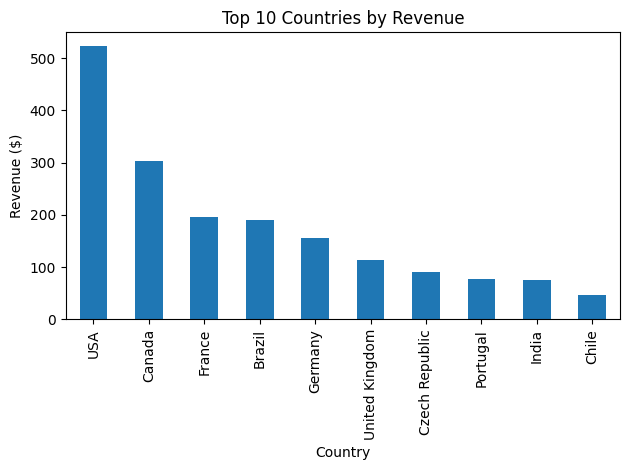

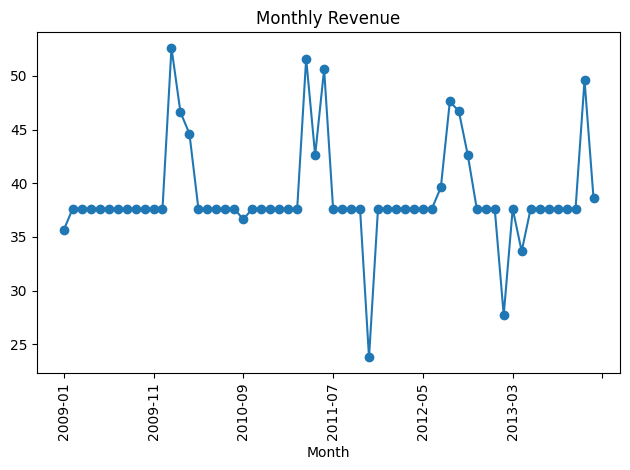

                          Track  Revenue
0                The Woman King     3.98
1                       The Fix     3.98
2                     Walkabout     3.98
3                      Hot Girl     3.98
4                Gay Witch Hunt     3.98
5             Phyllis's Wedding     3.98
6  How to Stop an Exploding Man     3.98
7                         Pilot     3.98
8        Occupation / Precipice     1.99
9                 Exodus, Pt. 1     1.99


In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("Chinook_Sqlite.sqlite")

# Revenue per country
df_country = pd.read_sql_query("""
    SELECT BillingCountry AS Country, ROUND(SUM(Total),2) AS Revenue
    FROM Invoice GROUP BY BillingCountry ORDER BY Revenue DESC LIMIT 10
""", conn)
df_country.plot(kind="bar", x="Country", y="Revenue", legend=False, title="Top 10 Countries by Revenue")
plt.ylabel("Revenue ($)")
plt.tight_layout()
plt.savefig("revenue_by_country.png")
plt.show()

# Monthly revenue
df_month = pd.read_sql_query("""
    SELECT strftime('%Y-%m', InvoiceDate) AS Month, ROUND(SUM(Total),2) AS Revenue
    FROM Invoice GROUP BY Month ORDER BY Month
""", conn)
df_month.plot(x="Month", y="Revenue", marker="o", title="Monthly Revenue", legend=False)
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("monthly_revenue.png")
plt.show()

# Top 10 tracks
df_tracks = pd.read_sql_query("""
    SELECT t.Name AS Track, ROUND(SUM(il.UnitPrice*il.Quantity),2) AS Revenue
    FROM InvoiceLine il JOIN Track t ON il.TrackId=t.TrackId
    GROUP BY t.TrackId ORDER BY Revenue DESC LIMIT 10
""", conn)
print(df_tracks)
conn.close()

## Key Business Insights

**Total revenue analyzed: $2,328.60** (verified: country totals match the invoice total)

1. **The USA is the strongest market.** It generated $523.06 from 91 orders, about 22% of total revenue. Canada is second ($303.96) and France third ($195.10). The top 3 countries together bring in about 44% of all revenue.

2. **Rock is the top-selling genre by a wide margin.** Rock earned $826.65, about 35% of revenue and more than double Latin ($382.14). Rock, Latin, Metal ($261.36) and Alternative & Punk ($241.56) together make up about 73% of revenue.

3. **Monthly revenue is stable, with a few spikes and dips.** Most months earn about $37.62 from 7 orders.
   - Strongest months: 2010-01 ($52.62), 2011-04 ($51.62), 2011-06 ($50.62).
   - Weakest months: 2011-11 ($23.76), 2013-02 ($27.72), 2013-04 ($33.66).
   - The weakest month (2011-11) was about 37% below a typical month.

4. **Customer spending is evenly spread.** Top spenders in each country are close together (for example Astrid Gruber in Austria spent $42.62, François Tremblay in Canada $39.62, Luís Gonçalves in Brazil $39.62). No single customer drives the business, so the risk of depending on one big customer is low.

5. **There is no single "hit" product.** Eight tracks are tied at $3.98 (2 units each), so sales are spread across the catalog instead of a few blockbusters.

### Recommendations
- Focus marketing on the **USA, Canada and France**, which bring in about 44% of revenue.
- Promote **Rock and Latin** content, since these genres drive the most sales.
- Run promotions before and during weak periods (like late 2011 and early 2013) to smooth out the dips.
- Offer loyalty rewards to the top customers in each country.

